# Exploratory Data Analysis on Unicorn Dataset

### Data pre-processing

In [6]:
import pandas as pd
import numpy as np
import geopandas as gpd
import networkx as nx
import seaborn as sns
import statsmodels.api as sm
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [8]:
# Load the dataset
unicornData = pd.read_csv("Unicorn_Companies.csv")

##### Show the dataset entries and properties for better understanding how the dataset looks like

In [9]:
# First rows of Dataset
unicornData.head()

,Company,Valuation ($B),Date Joined,Country,City,Industry,Select Inverstors,Founded Year,Total Raised,Financial Stage,Investors Count,Deal Terms,Portfolio Exits
0,Bytedance,$140,4/7/2017,China,Beijing,Artificial intelligence,"Sequoia Capital China, SIG Asia Investments, S...",2012.0,$7.44B,IPO,28.0,8.0,5.0
1,SpaceX,$100.3,12/1/2012,United States,Hawthorne,Other,"Founders Fund, Draper Fisher Jurvetson, Rothen...",2002.0,$6.874B,NaN,29.0,12.0,NaN
2,Stripe,$95,1/23/2014,United States,San Francisco,Fintech,"Khosla Ventures, LowercaseCapital, capitalG",2010.0,$2.901B,Asset,39.0,12.0,1.0
3,Klarna,$45.6,12/12/2011,Sweden,Stockholm,Fintech,"Institutional Venture Partners, Sequoia Capita...",2005.0,$3.472B,Acquired,56.0,13.0,1.0
4,Epic Games,$42,10/26/2018,United States,Cary,Other,"Tencent Holdings, KKR, Smash Ventures",1991.0,$4.377B,Acquired,25.0,5.0,2.0


In [10]:
# Description of the Dataset 
unicornData.describe()

,Founded Year,Investors Count,Deal Terms,Portfolio Exits
count,994.000000,1036.000000,1008.000000,49.000000
mean,2012.710262,14.432432,3.093254,1.346939
std,5.942876,9.946537,2.159764,0.751416
min,1919.000000,1.000000,1.000000,1.000000
25%,2011.000000,8.000000,1.000000,1.000000
50%,2014.000000,13.000000,3.000000,1.000000
75%,2016.000000,19.000000,4.000000,1.000000
max,2021.000000,91.000000,19.000000,5.000000


In [11]:
# Shape of the Dataset
unicornData.shape

(1037, 13)

In [12]:
# Columns of the Dataset
unicornData.columns

Index(['Company', 'Valuation ($B)', 'Date Joined', 'Country', 'City',
       'Industry', 'Select Inverstors', 'Founded Year', 'Total Raised',
       'Financial Stage', 'Investors Count', 'Deal Terms', 'Portfolio Exits'],
      dtype='str')

In [13]:
# Check for the datatype and existing Null values in the dataset
unicornData.info()

<class 'pandas.DataFrame'>
RangeIndex: 1037 entries, 0 to 1036
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Company            1037 non-null   str    
 1   Valuation ($B)     1037 non-null   str    
 2   Date Joined        1037 non-null   str    
 3   Country            1037 non-null   str    
 4   City               1037 non-null   str    
 5   Industry           1037 non-null   str    
 6   Select Inverstors  1020 non-null   str    
 7   Founded Year       994 non-null    float64
 8   Total Raised       1013 non-null   str    
 9   Financial Stage    49 non-null     str    
 10  Investors Count    1036 non-null   float64
 11  Deal Terms         1008 non-null   float64
 12  Portfolio Exits    49 non-null     float64
dtypes: float64(4), str(9)
memory usage: 105.4 KB


##### Before performing any analysis, it is important to ensure that each column has the correct data type. The following cell converts the dataset columns to suitable data types, allowing for accurate calculations, data manipulation, visualization, and time series analysis.

In [14]:
# Converting Valuation column to the float and also remove the dollar sign
unicornData['Valuation ($B)'] = unicornData['Valuation ($B)'].str.replace('$', '').astype('float64')
# Converting Date Joined Column to DateTime format and extract year
unicornData['Date Joined'] = pd.to_datetime(unicornData['Date Joined'])
unicornData['Year_Joined'] = unicornData['Date Joined'].dt.year

In [15]:
# Countries in dataset
unicornData['Country'].value_counts()
# Cities in the dataset
unicornData['City'].value_counts()

City
San Francisco    145
New York          96
Beijing           63
Shanghai          43
London            33
                ... 
Alexandria         1
Ottawa             1
Petah Tikva        1
Hyderabad          1
Milan              1
Name: count, Length: 256, dtype: int64

### Group the data for better visualization

In [16]:
grouped1 = unicornData.groupby('Country')['City'].apply(list).reset_index()

# Creating a dictionary from the grouped DataFrame
country_city_dict = dict(zip(grouped1['Country'], grouped1['City']))
print(country_city_dict)

{'Argentina': ['Buenos Aires'], 'Australia': ['Surry Hills', 'Melbourne', 'Sydney', 'Richmond', 'Brisbane', 'Alexandria'], 'Austria': ['Vienna', 'Vienna'], 'Bahamas': ['Fintech'], 'Belgium': ['Brussels', 'Louvain-la-Neuve', 'Ghent'], 'Bermuda': ['Hamilton'], 'Brazil': ['Campinas', 'Sao Paulo', 'Sao Paulo', 'Sao Paulo', 'Sao Paulo', 'Sao Paulo', 'Sao Paulo', 'Sao Paulo', 'Curitiba', 'Sao Paulo', 'Sao Paulo', 'Osasco', 'Curitiba', 'Parana', 'Sao Paulo', 'Sao Paulo'], 'Canada': ['Vancouver', 'Toronto', 'Montreal', 'Montreal', 'Mississauga', 'Vancouver', 'Kitchener', 'Toronto', 'Vancouver', 'Burnaby', 'Toronto', 'Vancouver', 'Toronto', 'Waterloo', 'Toronto', 'Vancouver', 'Toronto', 'Ottawa', 'Waterloo'], 'Chile': ['Santiago', 'Santiago'], 'China': ['Beijing', 'Shanghai', 'Beijing', 'Shenzhen', 'Shenzhen', 'Beijing', 'Beijing', 'Shanghai', 'Luohe', 'Shenzhen', 'Beijing', 'Changsha', 'Hangzhou', 'Beijing', 'Shenzhen', 'Beijing', 'Beijing', 'Shanghai', 'Shanghai', 'Beijing', 'Shanghai', 'Beij

In [23]:
import os

print(os.getcwd())
print(os.listdir())

/Users/gopinathji/Downloads/EDA on Unicorn Dataset
['.DS_Store', 'Untitled.ipynb', 'Unicorn_Companies.csv', '.ipynb_checkpoints', 'ne_110m_admin_0_countries', 'unicorn-companies-eda.ipynb', 'ne_110m_admin_0_countries 2']


In [31]:
import geopandas as gpd
import matplotlib.pyplot as plt

# Group by country and count the number of cities
grouped = unicornData.groupby('Country').size().reset_index(name='CityCount')

# Define macro regions
macro_regions = {
    'North America': ['United States', 'Canada'],
    'South America': ['Brazil'],
    'Europe': ['Germany', 'United Kingdom', 'France', 'Israel'],
    'Asia': ['China', 'India', 'Japan', 'Singapore', 'South Korea']
}

# Function to assign macro-region
def assign_macro_region(country):
    for region, countries in macro_regions.items():
        if country in countries:
            return region
    return 'Other'

# Create MacroRegion column
grouped['MacroRegion'] = grouped['Country'].apply(assign_macro_region)

# Plot the macro-regions
# Load the downloaded Natural Earth world map dataset from the local directory
world = gpd.read_file("/Users/gopinathji/Downloads/EDA on Unicorn Dataset/ne_110m_admin_0_countries")

# Merge world map with the macro-regions
world = world.merge(grouped, how='left', left_on='SOVEREIGNT', right_on='Country') # the column name in the Natural Earth data is 'SOVEREIGNT' for country names

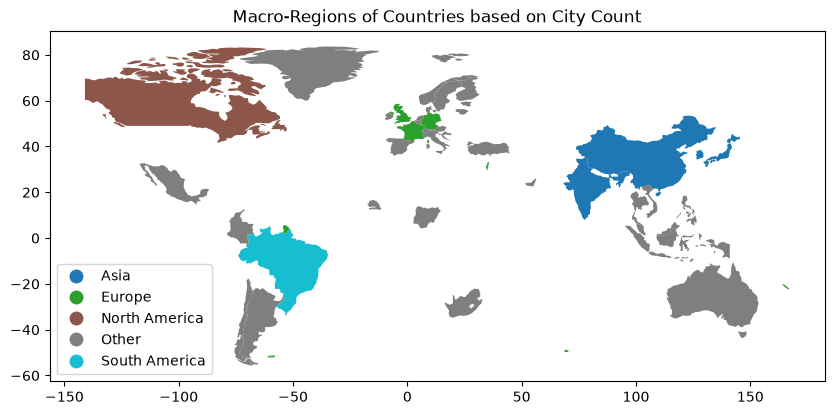

In [27]:
# Plot the world map with macro-regions colored
fig, ax = plt.subplots(1, 1, figsize=(10, 8))
world.plot(column='MacroRegion', ax=ax, legend=True,
           legend_kwds={'loc': 'lower left'}, cmap='tab10')
ax.set_title('Macro-Regions of Countries based on City Count')
plt.show()

## Insights

- The choropleth map illustrates the global distribution of unicorn companies across different countries.
- Countries with darker shades represent a higher concentration of cities hosting unicorn companies, indicating stronger startup ecosystems.
- North America, Europe, and Asia contain the highest concentration of unicorn companies, highlighting their leadership in technological innovation, entrepreneurship, and venture capital investment.
- The visualization provides valuable insights into regional economic development and the global distribution of high-growth startups.
- Overall, the map helps identify geographical trends and highlights regions that play a significant role in the global startup ecosystem.

In [28]:
# Filter countries with more than 15 cities count
countries_with_more_than_15_cities = list(grouped[grouped['CityCount'] > 15]['Country'])

# Create a dictionary with country names and their corresponding city counts
filtered_country_city_dict = {country: grouped[grouped['Country'] == country]['CityCount'].iloc[0] for country in countries_with_more_than_15_cities}

# Extract filtered countries and cities count
filtered_countries = list(filtered_country_city_dict.keys())
filtered_num_cities = list(filtered_country_city_dict.values())

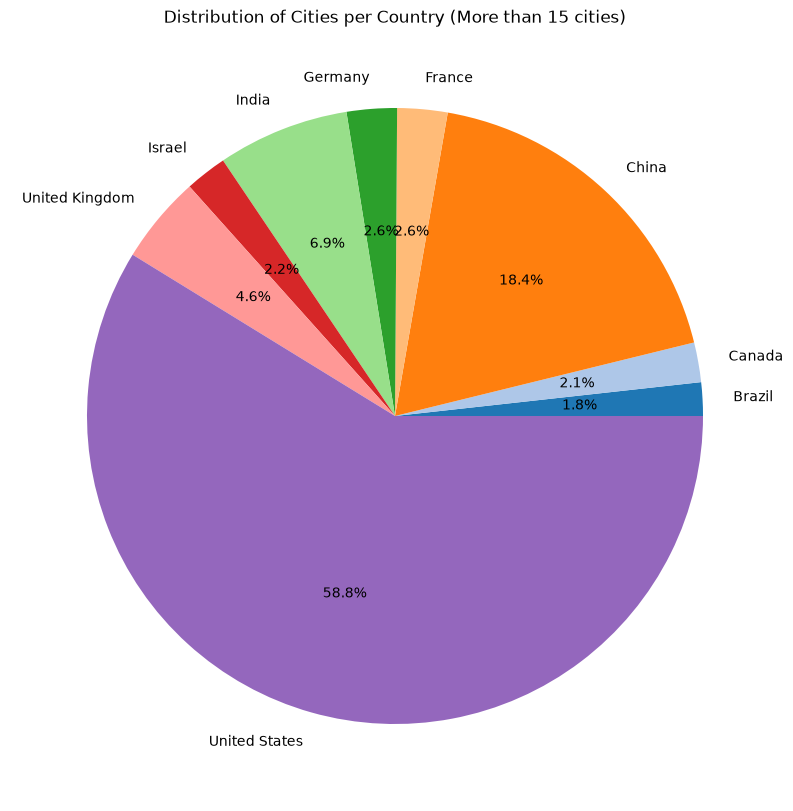

In [29]:
# Plot the data using a pie chart
plt.figure(figsize=(10, 10))
plt.pie(filtered_num_cities, labels=filtered_countries, autopct='%1.1f%%', colors=plt.cm.tab20.colors)
plt.title('Distribution of Cities per Country (More than 15 cities)')
plt.show()

## Insights

- The pie chart illustrates the distribution of countries with more than 15 unicorn-hosting cities across different macro-regions.
- North America, Europe, and Asia account for the majority of these countries, highlighting their strong startup ecosystems and innovation capabilities.
- The concentration of unicorn companies in these regions reflects favorable economic conditions, increased venture capital investment, and supportive business environments.
- Regions with a higher number of unicorn-hosting cities often attract entrepreneurs, investors, and skilled professionals, fostering technological advancement and economic growth.
- Overall, the visualization provides valuable insights into the global distribution of startup hubs and emphasizes the relationship between regional development and entrepreneurial success.

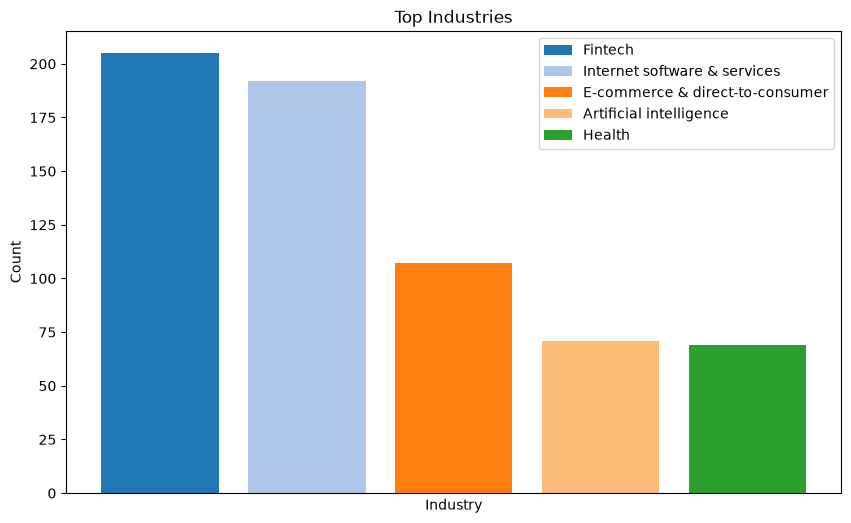

In [30]:
# Number of Industry types in the dataset
industry_counts = unicornData['Industry'].value_counts()

# Determine the threshold count for grouping industries
threshold_count = 60  # You can adjust it as needed

# Get the counts of the top industries
top_industries = industry_counts[industry_counts >= threshold_count]

# Plotting the data for top industries only with different colors for each bar
colors = plt.cm.tab20(np.arange(len(top_industries)))  # Generate different colors
plt.figure(figsize=(10, 6))
for i, (industry, count) in enumerate(top_industries.items()):
    plt.bar(industry, count, color=colors[i], label=industry)

plt.xlabel('Industry')
plt.ylabel('Count')
plt.title('Top Industries')
plt.xticks([])  # Remove x-axis ticks
plt.legend(top_industries.index, loc='upper right')  # Add legend with all labels
plt.show()

## Insights

- The bar chart illustrates the distribution of unicorn companies across different industries.
- Industries with higher counts indicate a stronger presence within the global unicorn ecosystem, reflecting sectors with greater innovation and investment activity.
- The visualization enables an easy comparison of unicorn company counts across industries, helping identify the most dominant and emerging sectors.
- Technology-related industries typically account for a significant share of unicorn companies, highlighting the increasing importance of digital transformation and innovation.
- Overall, the chart provides valuable insights into industry trends and the sectors driving the growth of high-value startups.

In [32]:
# Load the downloaded Natural Earth world map dataset from the local directory
world = gpd.read_file("/Users/gopinathji/Downloads/EDA on Unicorn Dataset/ne_110m_admin_0_countries")

# Convert industry names to lowercase for normalization
unicornData['Industry'] = unicornData['Industry'].str.lower()
# Get the counts of the top industries also with the lowercase
top_industries1 = industry_counts[industry_counts >= threshold_count].index.str.lower()

# Filter dataset for entries where the industry is one of the top industries
top_industries_data = unicornData[unicornData['Industry'].isin(top_industries1)]

# Group by country and industry, then count the number of companies in each group
country_industry_counts = top_industries_data.groupby(['Country', 'Industry']).size().unstack(fill_value=0)

# Merge world map with country_industry_counts
world = world.merge(country_industry_counts, how='left', left_on='SOVEREIGNT', right_on='Country') # the column name in the Natural Earth data is 'SOVEREIGNT' for country names

<Figure size 1400x1200 with 0 Axes>

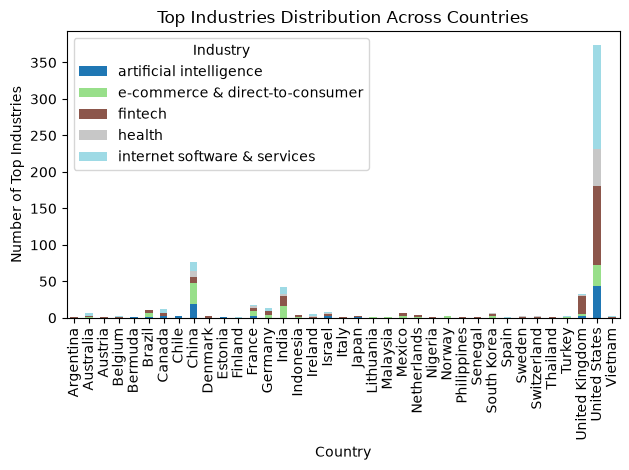

In [33]:
# Plotting the data
plt.figure(figsize=(14, 12))
country_industry_counts.plot(kind='bar', stacked=True, cmap='tab20')
plt.ylabel('Number of Top Industries')
plt.xlabel('Country')
plt.title('Top Industries Distribution Across Countries')
plt.yticks(rotation=0)  # Rotate y-axis labels for better readability
plt.tight_layout()  # Adjust layout to prevent overlapping labels
plt.show()

## Insights

- The stacked bar chart illustrates the distribution of top unicorn industries across different countries.
- Each bar represents a country, while the stacked segments show the contribution of different industries, making it easy to identify the dominant sectors within each country.
- By comparing the total heights of the bars, we can observe which countries have a larger number of unicorn companies across multiple industries.
- The variation in the composition of the stacked bars highlights the diversity of economic activities and startup ecosystems among countries.
- Overall, the visualization provides valuable insights into the relationship between countries and their leading industries, helping identify global trends in innovation and entrepreneurship.

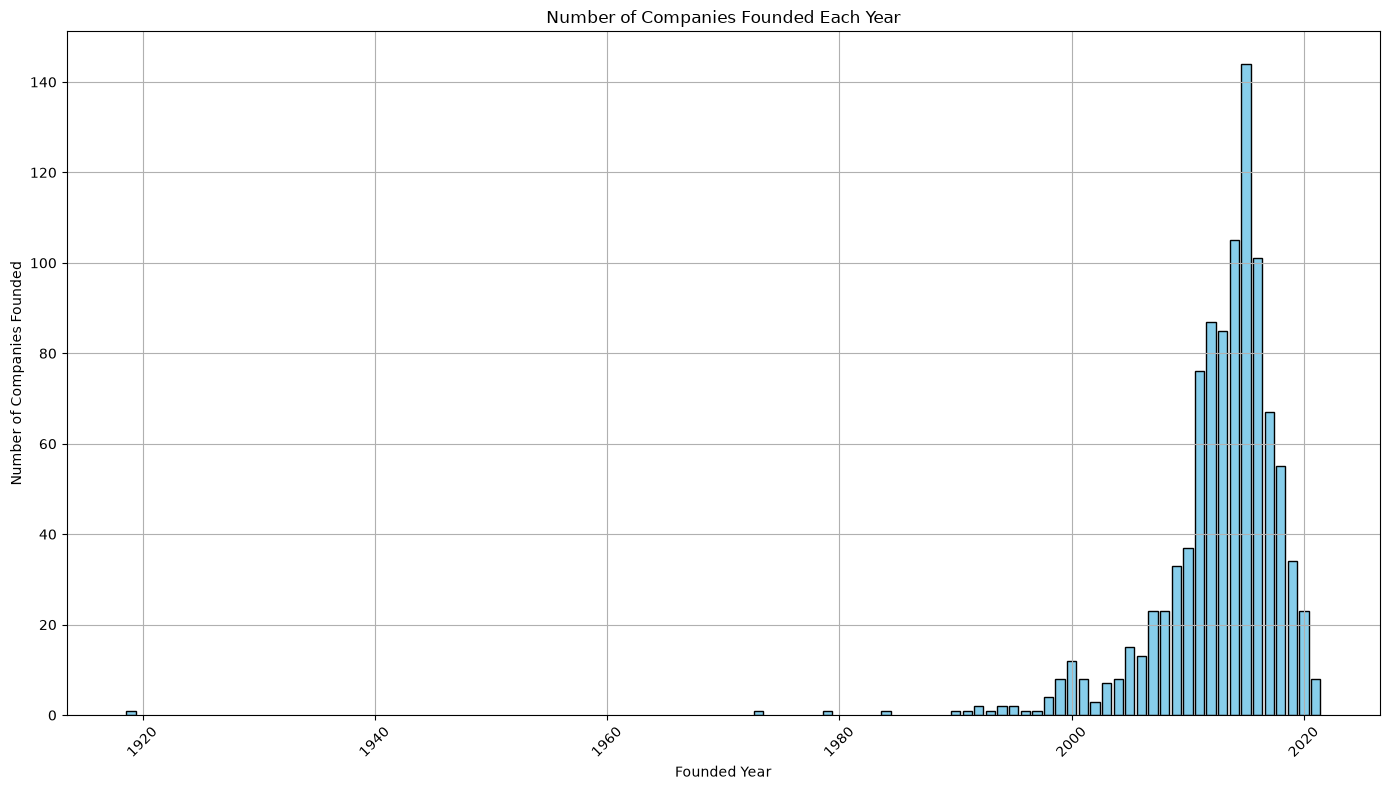

In [34]:
# Drop rows with missing values in the 'Founded Year' column
df_cleaned = unicornData.dropna(subset=['Founded Year'])

# Group by 'Founded Year' and aggregate the count of companies and the list of companies
grouped = df_cleaned.groupby('Founded Year')['Company'].agg(['count', list])

# Plotting a bar chart
plt.figure(figsize=(14, 8))
bars = plt.bar(grouped.index, grouped['count'], color='skyblue', edgecolor='black')
plt.xlabel('Founded Year')
plt.ylabel('Number of Companies Founded')
plt.title('Number of Companies Founded Each Year')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

## Insights

- The bar chart illustrates the number of unicorn companies founded each year, providing a clear overview of founding trends over time.
- Variations in the number of companies founded across different years highlight periods of growth and decline in entrepreneurial activity.
- Years with a higher number of company foundations may reflect favorable economic conditions, increased venture capital investment, or rapid technological advancements.
- Conversely, years with fewer company foundations may indicate economic slowdowns, market uncertainty, or changes in industry dynamics.
- Overall, the visualization helps identify long-term trends in startup formation and provides insights into the evolution of the global unicorn ecosystem.

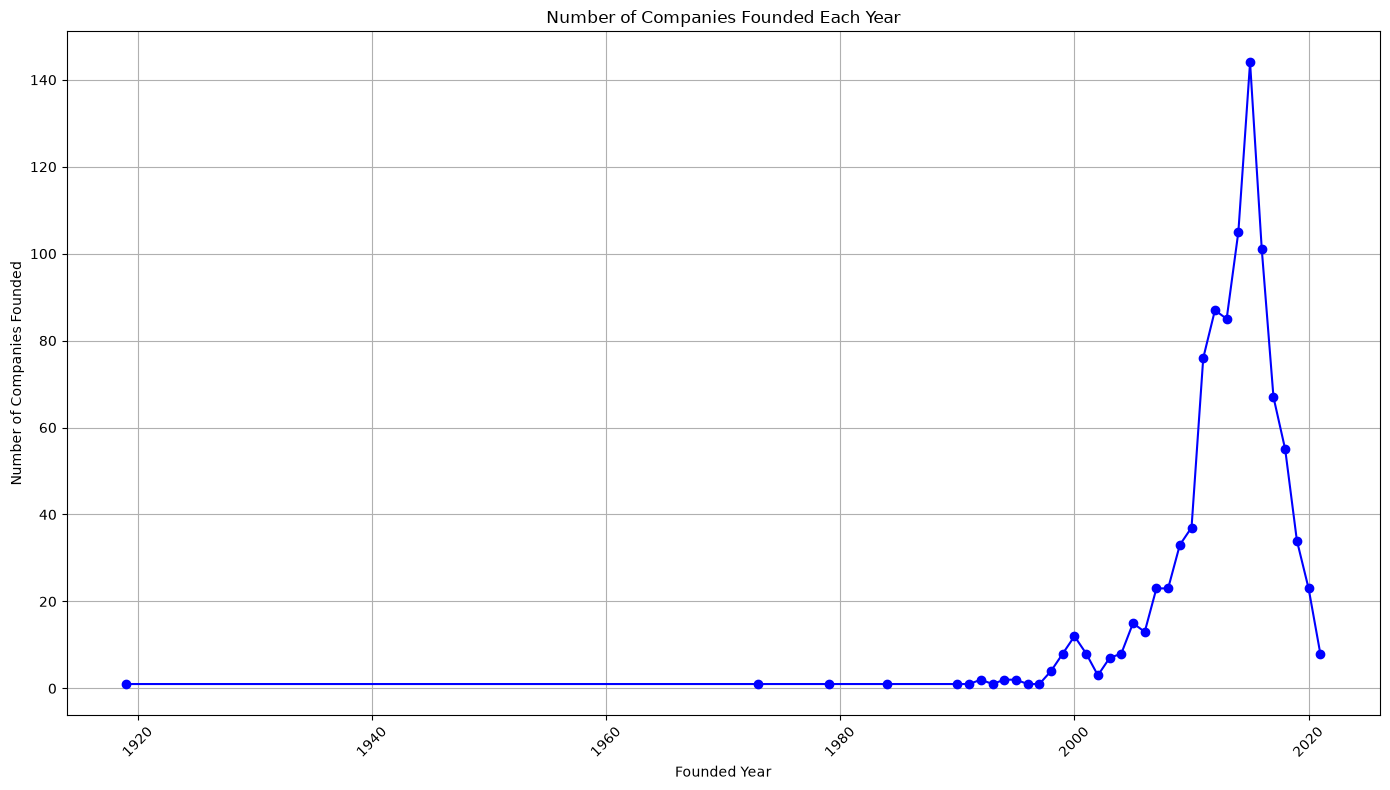

In [35]:
# Drop rows with missing values in the 'Founded Year' column
df_cleaned = unicornData.dropna(subset=['Founded Year'])

# Group by 'Founded Year' and aggregate the count of companies
grouped = df_cleaned.groupby('Founded Year')['Company'].count()

# Plotting a line chart for the time series
plt.figure(figsize=(14, 8))
plt.plot(grouped.index, grouped.values, marker='o', color='blue', linestyle='-')
plt.xlabel('Founded Year')
plt.ylabel('Number of Companies Founded')
plt.title('Number of Companies Founded Each Year')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

## Insights

- The line chart illustrates the trend in the number of unicorn companies founded over time, providing a clear view of historical changes in company formation.
- Compared with the previous bar chart, the line chart makes it easier to identify long-term trends, growth patterns, and fluctuations across different years.
- Periods of increasing company foundations may indicate favorable market conditions, technological advancements, or higher investment activity.
- Declines in the trend may reflect economic slowdowns, market uncertainty, or changes in the entrepreneurial landscape.
- Overall, the visualization provides valuable insights into the evolution of the global unicorn ecosystem and highlights how startup formation has changed over time.

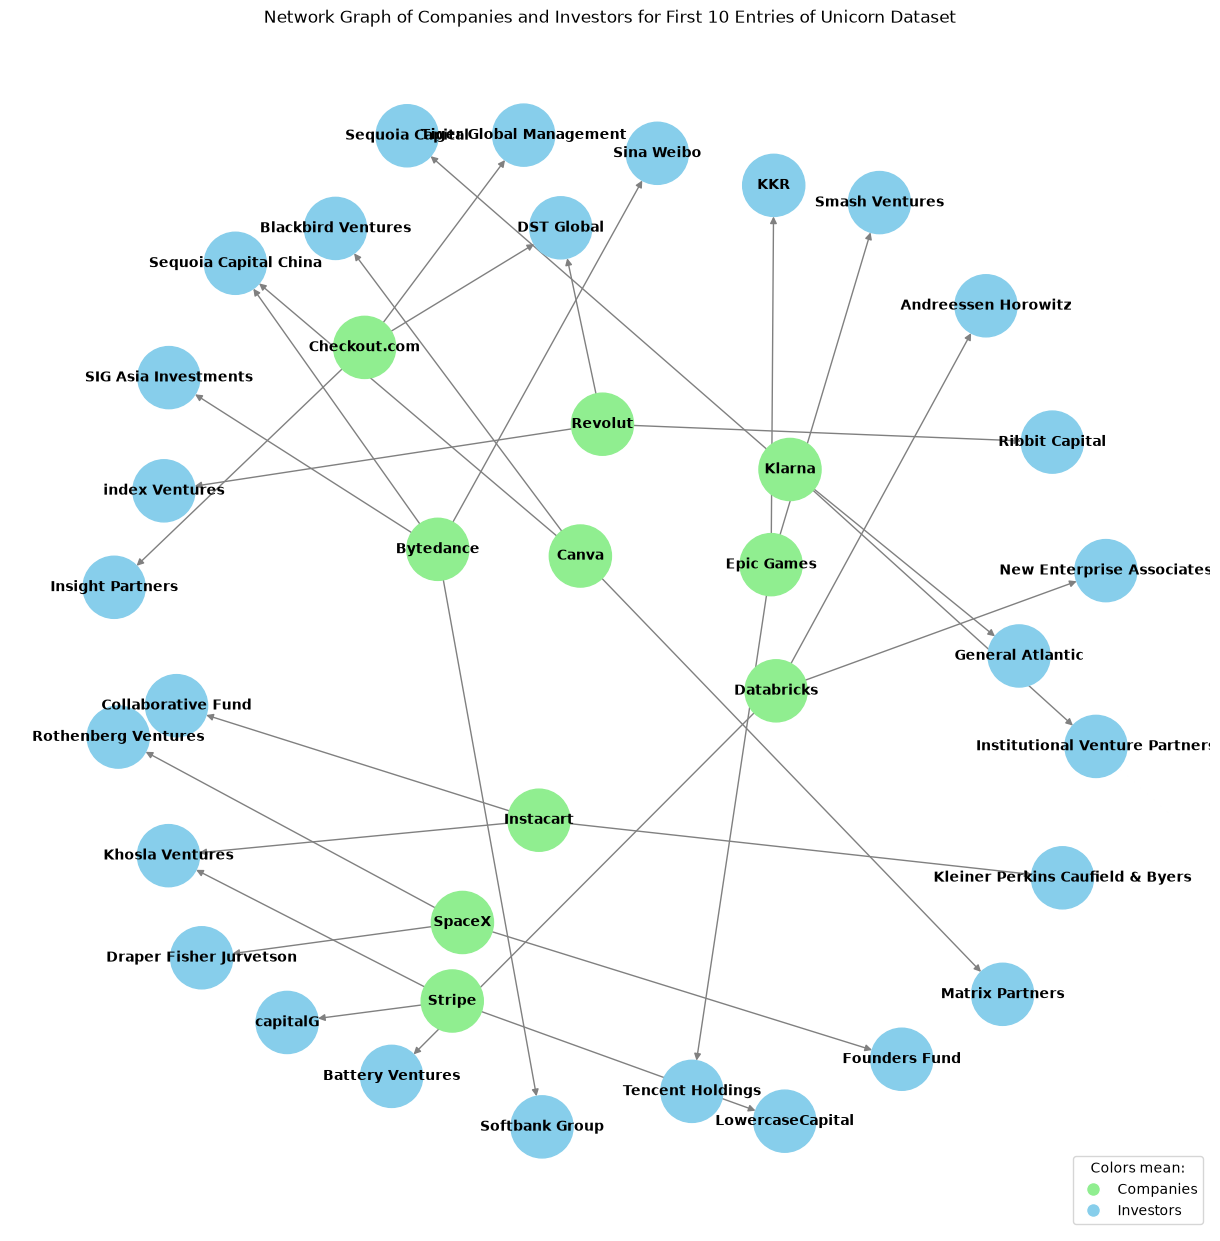

In [36]:
subset_data = unicornData.head(10)
# Create a directed graph
G = nx.DiGraph()

# Add companies and investors as nodes
for index, row in subset_data.iterrows():
    company = row['Company']
    investors = row['Select Inverstors'].split(',')
    G.add_node(company, node_type='company')
    for investor in investors:
        G.add_node(investor.strip(), node_type='investor')
        G.add_edge(company,investor.strip())

# Assign different colors to nodes based on their type
node_colors = {'company': 'lightgreen', 'investor': 'skyblue'}
colors = [node_colors[G.nodes[node]['node_type']] for node in G.nodes]


# Draw the graph
plt.figure(figsize=(12, 12))
pos = nx.spring_layout(G)  # Layout for the graph
nx.draw(G, pos, with_labels=True, node_size=2000, node_color=colors, font_size=10, font_weight='bold', edge_color='gray', arrowsize=10)
legend_labels = {'Companies': 'lightgreen', 'Investors': 'skyblue'}
legend_handles = [plt.Line2D([0], [0], marker='o', color='w', label=label, markerfacecolor=color, markersize=10) for label, color in legend_labels.items()]
plt.legend(handles=legend_handles, title='Colors mean:', loc='lower right')
plt.title('Network Graph of Companies and Investors for First 10 Entries of Unicorn Dataset')
plt.show()

## Insights

- The network graph visualizes the relationships between unicorn companies and their investors, providing an overview of the investment ecosystem.
- Nodes represent companies and investors, while the connecting edges indicate direct investment relationships between them.
- Companies connected to multiple investors may have attracted greater funding and stronger market confidence, whereas investors linked to multiple companies indicate diversified investment portfolios.
- The network structure helps identify key investors, highly connected companies, and clusters that play an important role in the startup ecosystem.
- Overall, the visualization provides valuable insights into investment patterns, stakeholder connectivity, and collaboration opportunities within the global unicorn network.

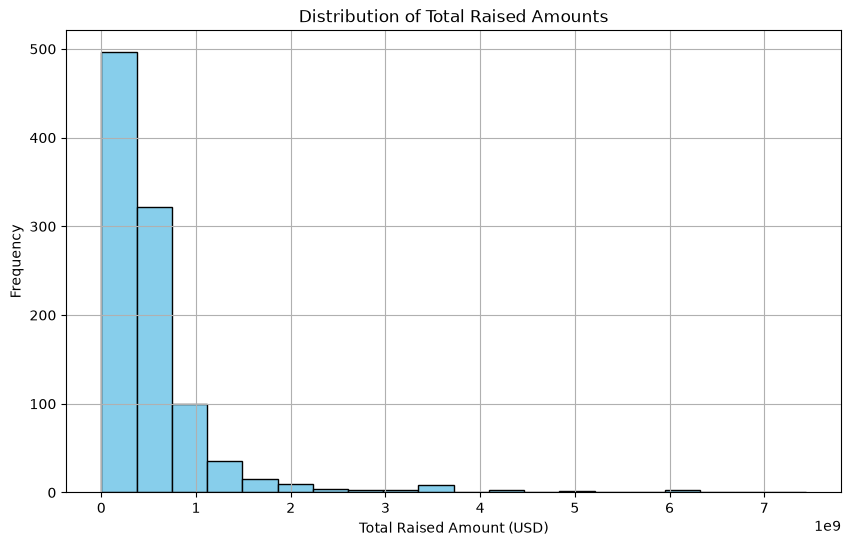

In [37]:
# Plot the Total Raised data
# First we clean and remove unnecessary data from this column
unicornData['Total Raised'] = pd.to_numeric(unicornData['Total Raised'].str.replace(r'[\$,]', '', regex=True).str.replace(r'[Bb]', 'e9', regex=True).str.replace(r'[Mm]', 'e6', regex=True), errors='coerce')


# Histogram of total raised amounts
plt.figure(figsize=(10, 6))
plt.hist(unicornData['Total Raised'], bins=20, color='skyblue', edgecolor='black')
plt.xlabel('Total Raised Amount (USD)')
plt.ylabel('Frequency')
plt.title('Distribution of Total Raised Amounts')
plt.grid(True)
plt.show()

## Insights

- The histogram illustrates the distribution of the total funding raised by unicorn companies, showing that most companies have secured relatively lower amounts of capital.
- The right-skewed distribution indicates that only a small number of companies have raised exceptionally large amounts of funding compared to the majority.
- The presence of high-value outliers suggests that a few unicorn companies have attracted substantial investments, likely due to strong growth potential, market leadership, or innovative business models.
- The distribution provides valuable insights into funding patterns and highlights the unequal allocation of investment across the startup ecosystem.
- Overall, the visualization helps identify funding trends and emphasizes the concentration of capital among a limited number of high-performing unicorn companies.

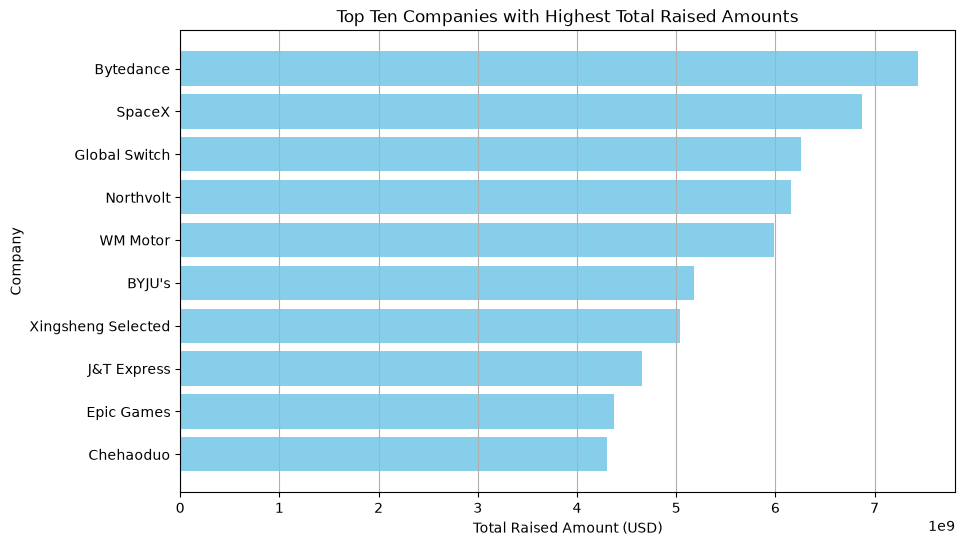

In [38]:
# Find the ten companies with the highest total raised amounts
top_ten_companies = unicornData.nlargest(10, 'Total Raised')[['Company', 'Total Raised']]

# Plotting
plt.figure(figsize=(10, 6))
plt.barh(top_ten_companies['Company'], top_ten_companies['Total Raised'], color='skyblue')
plt.xlabel('Total Raised Amount (USD)')
plt.ylabel('Company')
plt.title('Top Ten Companies with Highest Total Raised Amounts')
plt.gca().invert_yaxis()  # Invert y-axis to display the highest raised company at the top
plt.grid(axis='x')  # Add gridlines along the x-axis
plt.show()

## Insights

- The bar chart compares the total funding raised by unicorn companies, highlighting differences in their financial backing.
- Companies with higher funding levels are generally better positioned to accelerate innovation, expand into new markets, and strengthen their competitive advantage.
- Greater access to capital enables companies to invest in research and development, talent acquisition, infrastructure, and business expansion initiatives.
- The variation in funding across companies reflects differences in investor confidence, growth potential, and market opportunities.
- Overall, the visualization provides valuable insights into the financial strength of unicorn companies and the role of investment in supporting long-term business growth.

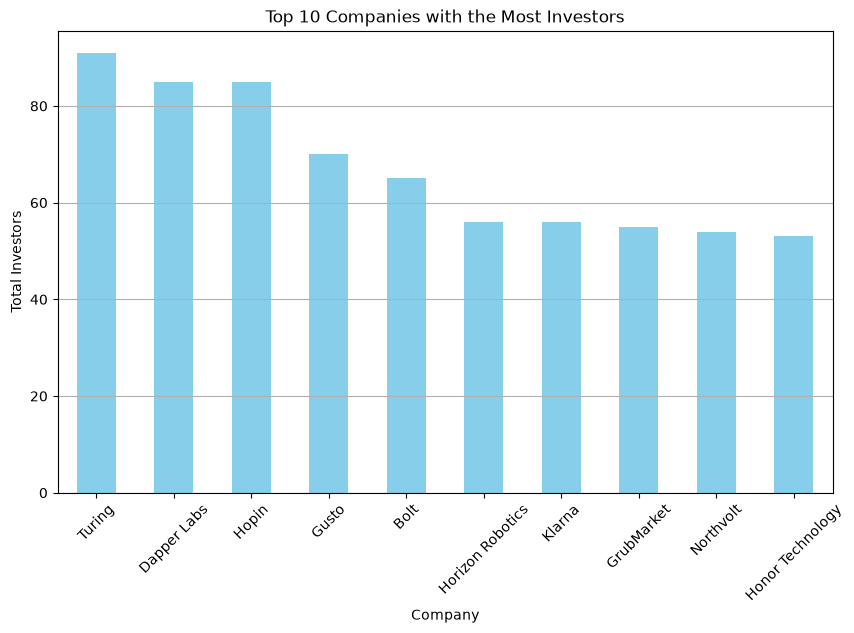

In [39]:
# Convert 'Investors Count' column to numeric
unicornData['Investors Count'] = pd.to_numeric(unicornData['Investors Count'], errors='coerce')

# Group by company name and sum the number of investors for each company
investors_per_company = unicornData.groupby('Company')['Investors Count'].sum()

# Sort the companies by the total number of investors and select the top 10
top_10_companies = investors_per_company.nlargest(10)

# Plotting
plt.figure(figsize=(10, 6))
top_10_companies.plot(kind='bar', color='skyblue')
plt.xlabel('Company')
plt.ylabel('Total Investors')
plt.title('Top 10 Companies with the Most Investors')
plt.xticks(rotation=45)  # Rotate x-axis labels for better readability
plt.grid(axis='y')  # Add gridlines along the y-axis
plt.show()

## Insights

- The chart highlights the top 10 unicorn companies with the highest number of investors.
- Companies with more investors indicate stronger investor confidence and broader financial support.
- A higher investor count may reflect strategic partnerships and greater market attractiveness.
- Overall, the visualization identifies leading companies that attract significant investment within the startup ecosystem.

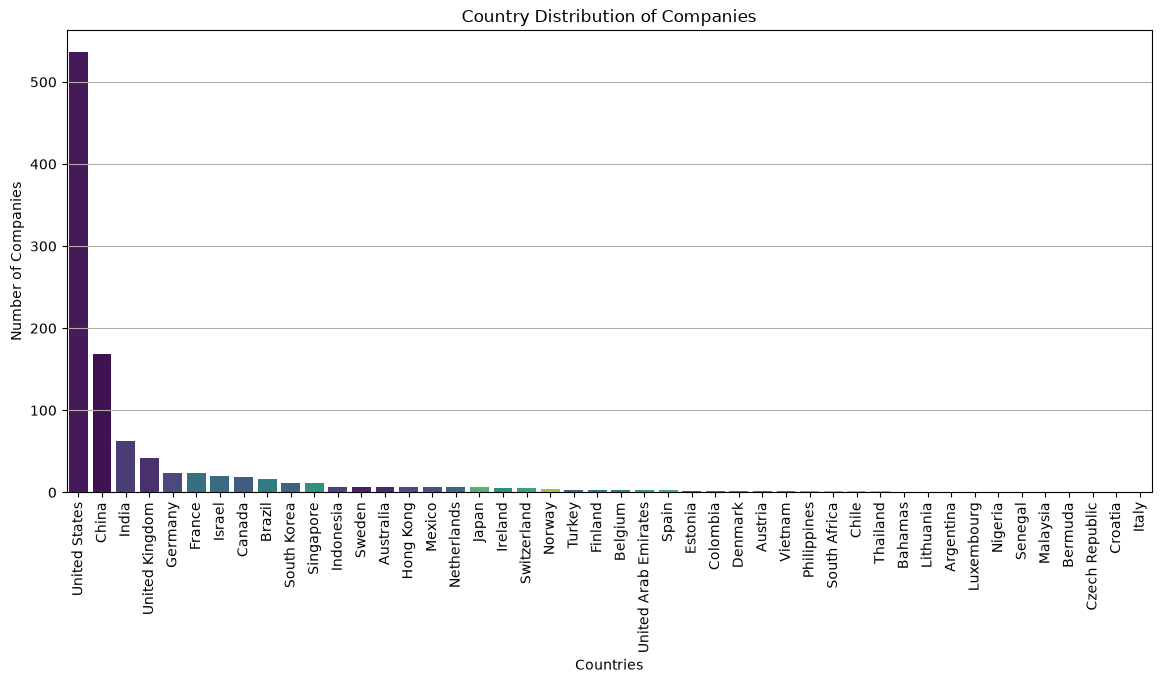

In [40]:
# Plotting
plt.figure(figsize=(14, 6))
sns.countplot(data=unicornData, x='Country', order=unicornData['Country'].value_counts().index, hue='Country', palette='viridis', legend=False)
plt.title('Country Distribution of Companies')
plt.xlabel('Countries')
plt.ylabel('Number of Companies')
plt.xticks(rotation=90)  # Rotate x-axis labels for better readability
plt.grid(axis='y')  # Add gridlines along the y-axis
plt.show()

## Insights

- The chart illustrates the distribution of unicorn companies across different countries, highlighting major startup hubs.
- Countries with a higher number of unicorn companies demonstrate stronger innovation ecosystems and entrepreneurial activity.
- The presence of unicorns in multiple regions reflects the growing global expansion of the startup ecosystem.
- Overall, the visualization provides insights into the geographical distribution and global reach of unicorn companies.

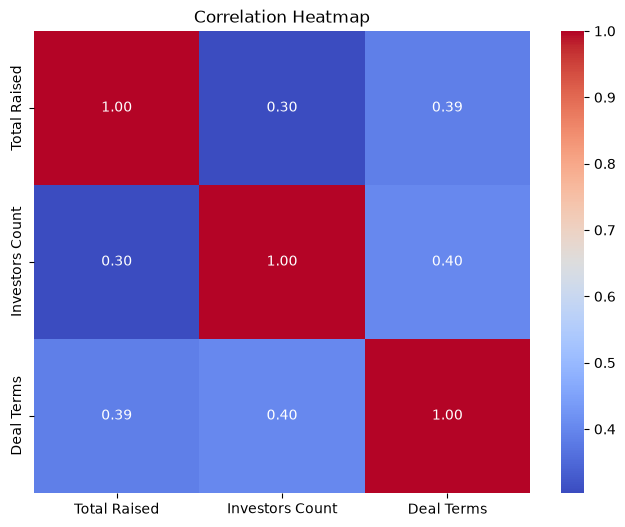

In [41]:
# Convert 'Deal Terms' column to integers
unicornData['Deal Terms'] = pd.to_numeric(unicornData['Deal Terms'], errors='coerce')

# Drop rows with NaN values in 'Deal Terms' and 'Total Raised' columns
unicornData.dropna(subset=['Deal Terms', 'Total Raised'], inplace=True)

# Compute correlation matrix
correlation_matrix = unicornData[['Total Raised', 'Investors Count', 'Deal Terms']].corr()

# Plot heatmap

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

## Insights

- The correlation matrix indicates a weak positive relationship between **Total Raised** and **Investors Count**, suggesting that companies with more investors tend to raise slightly more funding.
- A weak positive correlation is also observed between **Total Raised** and **Deal Terms**, indicating a limited association between funding and deal structure.
- The relationship between **Investors Count** and **Deal Terms** is weak, suggesting that the number of investors has little influence on deal terms.
- Overall, the heatmap shows that these variables exhibit only weak linear relationships, indicating that additional factors likely influence unicorn company funding and investment patterns.

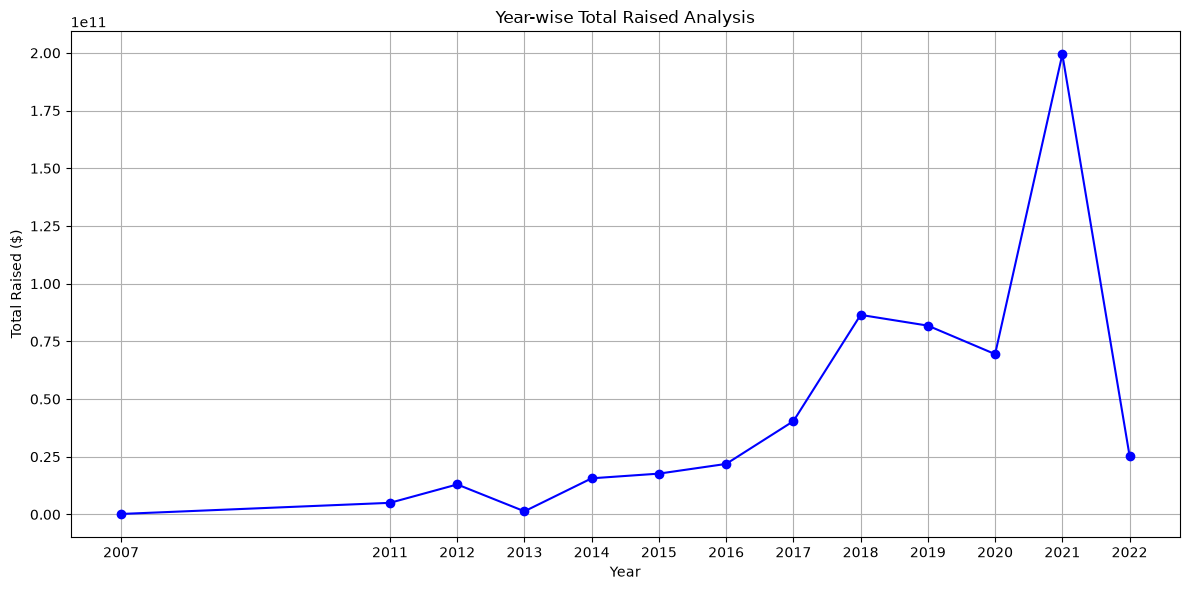

In [42]:
# Assuming 'unicornData' is your DataFrame with relevant columns: 'Valuation ($B)', 'Total Raised', 'Date Joined'

# Group the data by year and aggregate the metrics
yearly_metrics = unicornData.groupby('Year_Joined').agg({
    'Total Raised': 'sum',      # Sum of total raised for each year
}).reset_index()

# Plot the total raised over the years
plt.figure(figsize=(12, 6))

# Plot total raised over the years
plt.plot(yearly_metrics['Year_Joined'], yearly_metrics['Total Raised'], marker='o', color='blue')

# Customize plot
plt.title('Year-wise Total Raised Analysis')
plt.xlabel('Year')
plt.ylabel('Total Raised ($)')
plt.grid(True)
plt.xticks(yearly_metrics['Year_Joined'])  # Ensure all years are displayed on x-axis
plt.tight_layout()

# Show plot
plt.show()

## Insights

- The line chart illustrates the yearly trend in the total funding raised by unicorn companies.
- Peaks and declines in the trend highlight fluctuations in fundraising activity over different years.
- Periods of higher funding indicate stronger investment activity and favorable market conditions.
- Overall, the visualization provides insights into how fundraising has evolved over time within the global unicorn ecosystem.

In [43]:
# Convert 'Deal Terms' to numeric
unicornData['Deal Terms'] = pd.to_numeric(unicornData['Deal Terms'], errors='coerce')

# Drop rows with missing values
unicornData.dropna(subset=['Total Raised', 'Investors Count', 'Deal Terms'], inplace=True)

# Define predictor variables (X) and target variable (y)
X = unicornData[['Investors Count', 'Deal Terms']]
y = unicornData['Total Raised']

# Add constant to predictor variables
X = sm.add_constant(X)

# Fit regression model
model = sm.OLS(y, X).fit()

# Print summary of the regression model
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:           Total Raised   R-squared:                       0.175
Model:                            OLS   Adj. R-squared:                  0.173
Method:                 Least Squares   F-statistic:                     105.1
Date:                Tue, 21 Jul 2026   Prob (F-statistic):           4.13e-42
Time:                        16:32:16   Log-Likelihood:                -21615.
No. Observations:                 994   AIC:                         4.324e+04
Df Residuals:                     991   BIC:                         4.325e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
===================================================================================
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const            4.851e+07   4.32e+07      1.123      0.262   -3.63e+07    1.33e+08
Investors Count  1.328e+07   2.36e+06      5.632      0.000    8.65e+06    1.79e+07
Deal Terms       1.076e+08   1.08e+07      9.969      0.000    8.64e+07    1.29e+08
==============================================================================
Omnibus:                      950.247   Durbin-Watson:                   1.469
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            37094.025
Skew:                           4.454   Prob(JB):                         0.00
Kurtosis:                      31.571   Cond. No.                         36.9
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

## Insights

- The regression analysis indicates that **Investors Count** and **Deal Terms** are significant predictors of the **Total Raised** amount.
- Both variables show a statistically significant positive relationship with the funding raised by unicorn companies.
- However, the model's low **R-squared** value suggests that these variables explain only a small portion of the variation in total funding.
- Overall, the results indicate that additional factors beyond investors count and deal terms influence the funding raised by unicorn companies.

In [44]:
# Select relevant features for clustering
features = ['Total Raised', 'Investors Count']

# Drop rows with missing values in selected features
data_for_clustering = unicornData[features].dropna()

# Standardize the features
scaler = StandardScaler()
scaled_data = scaler.fit_transform(data_for_clustering)

# Determine the optimal number of clusters using the elbow method
inertia_values = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(scaled_data)
    inertia_values.append(kmeans.inertia_)

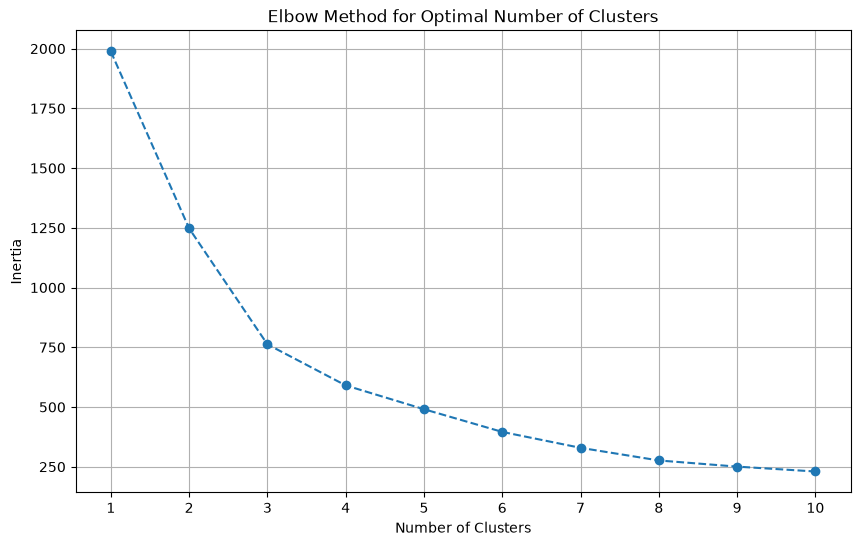

In [45]:
# Plot the elbow curve
plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), inertia_values, marker='o', linestyle='--')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal Number of Clusters')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

## Insights

- The elbow curve shows a sharp decrease in inertia from **1 to 3 clusters**, followed by a much slower rate of improvement.
- The **elbow point appears around 3 clusters**, indicating that **K = 3** is the optimal number of clusters for this dataset.
- Beyond **3 clusters**, the reduction in inertia becomes gradual, suggesting that adding more clusters provides only marginal improvements.
- Selecting **3 clusters** achieves a good balance between minimizing within-cluster variation and avoiding unnecessary model complexity.
- Overall, the elbow method suggests that the dataset can be effectively grouped into **three distinct clusters**.

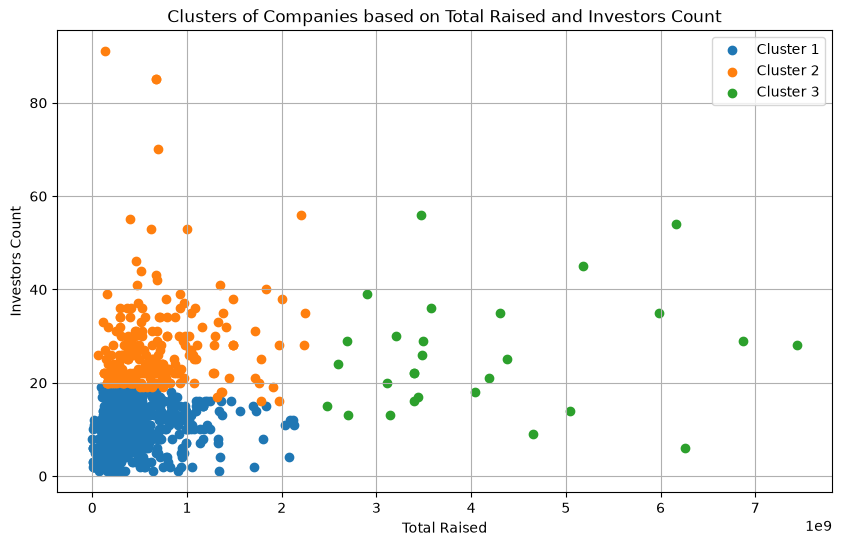

In [46]:
# Based on the elbow method, choose the optimal number of clusters
optimal_k = 3  # Adjust this based on the elbow curve

# Perform K-means clustering
kmeans = KMeans(n_clusters=optimal_k, random_state=42)
clusters = kmeans.fit_predict(scaled_data)

# Add cluster labels to the dataset
data_for_clustering['Cluster'] = clusters

# Plot the clusters
plt.figure(figsize=(10, 6))
for cluster in range(optimal_k):
    cluster_data = data_for_clustering[data_for_clustering['Cluster'] == cluster]
    plt.scatter(cluster_data['Total Raised'], cluster_data['Investors Count'], label=f'Cluster {cluster + 1}')

plt.xlabel('Total Raised')
plt.ylabel('Investors Count')
plt.title('Clusters of Companies based on Total Raised and Investors Count')
plt.legend()
plt.grid(True)
plt.show()

## Insights

- Clustering groups unicorn companies with similar characteristics, making it easier to identify common patterns and trends.
- The identified clusters can support market segmentation, investment analysis, and strategic business decision-making.
- Companies within the same cluster are likely to share similar funding, growth, or investment profiles.
- Overall, clustering provides valuable insights into the structure of the unicorn ecosystem and helps identify potential opportunities for investors and businesses.

# Final Project Summary

This project presents an exploratory data analysis (EDA) of the **Unicorn Companies Dataset** to understand global startup trends, investment patterns, funding behavior, and market characteristics. The analysis involved comprehensive data preprocessing, including handling missing values, converting data types, feature engineering, and preparing the dataset for visualization and modeling.

A variety of visualizations—including bar charts, line charts, pie charts, histograms, choropleth maps, network graphs, correlation heatmaps, and clustering techniques—were used to uncover meaningful insights. The analysis revealed that unicorn companies are highly concentrated in North America, Europe, and Asia, with technology-related industries dominating the global startup ecosystem. Funding distribution is highly right-skewed, indicating that while most unicorns raise moderate amounts of capital, a small number secure exceptionally large investments.

The study also explored relationships between funding, investor count, and deal terms using correlation analysis and multiple linear regression. The results showed statistically significant but relatively weak linear relationships, suggesting that additional business and market factors influence the total funding raised. Furthermore, K-Means clustering and the Elbow Method identified meaningful groups of companies with similar characteristics, supporting market segmentation and strategic decision-making.

Overall, the project demonstrates how data analytics and visualization can transform raw startup data into actionable business insights. The findings provide valuable information for investors, entrepreneurs, policymakers, and researchers seeking to better understand the global unicorn ecosystem, investment trends, and emerging opportunities in the startup landscape.